<a href="https://colab.research.google.com/github/medericl/Deep-Learning-pour-l-Image-/blob/main/05_ssd_student.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# Single Shot Multibox Detection

We previously introduced bounding boxes, anchor boxes,
multiscale object detection, and the dataset for object detection.
Now we are ready to use such background
knowledge to design an object detection model:
[single shot multibox detection
(SSD)](https://arxiv.org/abs/1512.02325).
This model is simple, fast, and widely used.
Although this is just one of vast amounts of
object detection models,
some of the design principles
and implementation details in this section
are also applicable to other models.


## Model

The figure below provides an overview of
the design of single-shot multibox detection.
This model mainly consists of
a base network
followed by
several multiscale feature map blocks.
The base network
is for extracting features from the input image,
so it can use a deep CNN.
For example,
the [original single-shot multibox detection paper](https://arxiv.org/abs/1512.02325)
adopts a VGG network truncated before the
classification layer,
while ResNet has also been commonly used.
Through our design
we can make the base network output
larger feature maps
so as to generate more anchor boxes
for detecting smaller objects.
Subsequently,
each multiscale feature map block
reduces (e.g., by half)
the height and width of the feature maps
from the previous block,
and enables each unit
of the feature maps
to increase its receptive field on the input image.


Recall the design
of multiscale object detection
through layerwise representations of images by
deep neural networks
in [Part 3](./03-multiscale-object-detection-student.ipynb).
Since
multiscale feature maps (the ones closer to the top of the figure below)
are smaller but have larger receptive fields,
they are suitable for detecting
fewer but larger objects.

In a nutshell,
via its base network and several multiscale feature map blocks,
single-shot multibox detection
generates a varying number of anchor boxes with different sizes,
and detects varying-size objects
by predicting classes and offsets
of these anchor boxes (thus the bounding boxes);
thus, this is a multiscale object detection model.


![As a multiscale object detection model, single-shot multibox detection mainly consists of a base network followed by several multiscale feature map blocks.](https://raw.githubusercontent.com/d2l-ai/d2l-en/e4f0ed18d9d83cd35434404daaf7ffc9631b5ece/img/ssd.svg)


In the following,
we will describe the implementation details
of different blocks in the previous figure. To begin with, we discuss how to implement
the class and bounding box prediction.





### Class Prediction Layer

Let the number of object classes be $q$.
Then **anchor boxes have $q+1$ classes,
where class 0 is background**.
At some scale,
suppose that the height and width of feature maps
are $h$ and $w$, respectively.
When $a$ anchor boxes
are generated with
each spatial position of these feature maps as their center,
a total of $hwa$ anchor boxes need to be classified.
This often makes classification with fully connected layers infeasible due to likely
heavy parametrization costs.
Instead, it is common to use channels of
convolutional layers to predict classes.
Single-shot multibox detection uses the
same technique to reduce model complexity.

Specifically,
the class prediction layer uses a convolutional layer
without altering width or height of feature maps.
In this way,
there can be a one-to-one correspondence
between outputs and inputs
at the same spatial dimensions (width and height)
of feature maps.
More concretely,
channels of the output feature maps
at any spatial position ($x$, $y$)
represent class predictions
for all the anchor boxes centered on
($x$, $y$) of the input feature maps.
To produce valid predictions,
there must be **$a(q+1)$ output channels**,
where for the same spatial position
the output channel with index $i(q+1) + j$
represents the prediction of
the class $j$ ($0 \leq j \leq q$)
for the anchor box $i$ ($0 \leq i < a$).

Below we define such a class prediction layer,
specifying $a$ and $q$ via arguments `num_anchors` and `num_classes`, respectively.
This layer uses a $3\times3$ convolutional layer with a
padding of 1.
The width and height of the input and output of this
convolutional layer remain unchanged.


In [67]:
%matplotlib inline
import torch
from torch import nn
from torch.nn import functional as F


In [68]:
from google.colab import files
#uploaded = files.upload()

In [69]:
#!unzip -q /content/dim3_data.zip -d /content/dim3
!ls /content/dim3

test  train  train.csv	val  val.csv


In [70]:
# Helpers adapted from Dive into Deep Learning (d2l 0.17.0, MIT-0 code).
# Authors: Aston Zhang, Zachary C. Lipton, Mu Li, Alexander J. Smola.
# https://github.com/d2l-ai/d2l-en ; https://d2l.ai/chapter_computer-vision/
# Local adaptations: no d2l/torchvision; explicit meshgrid indexing;
# configurable IoU threshold; device-safe matching/NMS; Pillow image loading.
# Maintainers: run embed_helpers.py after editing this file.
import hashlib

import os

from pathlib import Path

import urllib.request

import zipfile

import numpy as np

import pandas as pd

import torch

from PIL import Image

from matplotlib import pyplot as plt

DATA_DIR = '/content/dim3'

def set_figsize(figsize=(3.5, 2.5)):
    plt.rcParams['figure.figsize'] = figsize

def download_file(url, filename):
    """Download once into the current writable directory (no shell commands)."""
    path = Path(filename)
    if not path.is_file():
        temporary = path.with_suffix(path.suffix + '.part')
        try:
            with urllib.request.urlopen(url, timeout=60) as response:
                with temporary.open('wb') as output:
                    import shutil
                    shutil.copyfileobj(response, output)
            temporary.replace(path)
        finally:
            temporary.unlink(missing_ok=True)
    return path

def read_image(filename):
    """Read RGB uint8 pixels as a CHW tensor, without torchvision binaries."""
    with Image.open(filename) as image:
        return torch.from_numpy(np.array(image.convert('RGB'))).permute(2, 0, 1)

def download_bananas():
    """Use BANANA_DATA_DIR for an offline/Kaggle dataset, or download and verify."""
    override = os.environ.get('BANANA_DATA_DIR')
    data_dir = Path(override) if override else Path('banana-detection')
    if all((data_dir / split / 'label.csv').is_file()
           for split in ('bananas_train', 'bananas_val')):
        return data_dir
    if override:
        raise FileNotFoundError(f'Expected bananas_train/label.csv and bananas_val/label.csv in {data_dir}')
    archive = download_file(
        'https://d2l-data.s3-accelerate.amazonaws.com/banana-detection.zip',
        'banana-detection.zip')
    digest = hashlib.sha1()
    with archive.open('rb') as stream:
        for chunk in iter(lambda: stream.read(1024 * 1024), b''):
            digest.update(chunk)
    if digest.hexdigest() != '5de26c8fce5ccdea9f91267273464dc968d20d72':
        raise ValueError('Banana archive checksum mismatch; delete banana-detection.zip and retry.')
    with zipfile.ZipFile(archive) as zipped:
        destination = Path.cwd().resolve()
        for member in zipped.infolist():
            if not (destination / member.filename).resolve().is_relative_to(destination):
                raise ValueError('Unsafe archive path')
        zipped.extractall(destination)
    return data_dir

def read_data_bananas(is_train=True):
    """Read class IDs unchanged; normalize only xyxy coordinates."""
    split = download_bananas() / ('bananas_train' if is_train else 'bananas_val')
    rows = pd.read_csv(split / 'label.csv').set_index('img_name')
    images, targets = [], []
    for filename, row in rows.iterrows():
        image = read_image(split / 'images' / filename)
        target = torch.tensor(row.to_numpy(), dtype=torch.float32)
        height, width = image.shape[-2:]
        target[1:] /= torch.tensor([width, height, width, height])
        images.append(image)
        targets.append(target)
    return images, torch.stack(targets).unsqueeze(1)

def box_corner_to_center(boxes):
    """Convert from (upper-left, lower-right) to (center, width, height)."""
    x1, y1, x2, y2 = boxes[:, 0], boxes[:, 1], boxes[:, 2], boxes[:, 3]
    cx = (x1 + x2) / 2
    cy = (y1 + y2) / 2
    w = x2 - x1
    h = y2 - y1
    boxes = torch.stack((cx, cy, w, h), axis=-1)
    return boxes

def box_center_to_corner(boxes):
    """Convert from (center, width, height) to (upper-left, lower-right)."""
    cx, cy, w, h = boxes[:, 0], boxes[:, 1], boxes[:, 2], boxes[:, 3]
    x1 = cx - 0.5 * w
    y1 = cy - 0.5 * h
    x2 = cx + 0.5 * w
    y2 = cy + 0.5 * h
    boxes = torch.stack((x1, y1, x2, y2), axis=-1)
    return boxes

def bbox_to_rect(bbox, color):
    """Convert bounding box to matplotlib format."""
    # Convert the bounding box (upper-left x, upper-left y, lower-right x,
    # lower-right y) format to the matplotlib format: ((upper-left x,
    # upper-left y), width, height)
    return plt.Rectangle(xy=(bbox[0], bbox[1]), width=bbox[2] - bbox[0],
                             height=bbox[3] - bbox[1], fill=False,
                             edgecolor=color, linewidth=2)

def multibox_prior(data, sizes, ratios):
    """Generate anchor boxes with different shapes centered on each pixel."""
    in_height, in_width = data.shape[-2:]
    device, num_sizes, num_ratios = data.device, len(sizes), len(ratios)
    boxes_per_pixel = (num_sizes + num_ratios - 1)
    size_tensor = torch.tensor(sizes, device=device)
    ratio_tensor = torch.tensor(ratios, device=device)
    # Offsets are required to move the anchor to the center of a pixel. Since
    # a pixel has height=1 and width=1, we choose to offset our centers by 0.5
    offset_h, offset_w = 0.5, 0.5
    steps_h = 1.0 / in_height  # Scaled steps in y axis
    steps_w = 1.0 / in_width  # Scaled steps in x axis

    # Generate all center points for the anchor boxes
    center_h = (torch.arange(in_height, device=device) + offset_h) * steps_h
    center_w = (torch.arange(in_width, device=device) + offset_w) * steps_w
    shift_y, shift_x = torch.meshgrid(center_h, center_w, indexing="ij")
    shift_y, shift_x = shift_y.reshape(-1), shift_x.reshape(-1)

    # Generate `boxes_per_pixel` number of heights and widths that are later
    # used to create anchor box corner coordinates (xmin, xmax, ymin, ymax)
    w = torch.cat((size_tensor * torch.sqrt(ratio_tensor[0]),
                   sizes[0] * torch.sqrt(ratio_tensor[1:])))\
                   * in_height / in_width  # Handle rectangular inputs
    h = torch.cat((size_tensor / torch.sqrt(ratio_tensor[0]),
                   sizes[0] / torch.sqrt(ratio_tensor[1:])))
    # Divide by 2 to get half height and half width
    anchor_manipulations = torch.stack(
        (-w, -h, w, h)).T.repeat(in_height * in_width, 1) / 2

    # Each center point will have `boxes_per_pixel` number of anchor boxes, so
    # generate a grid of all anchor box centers with `boxes_per_pixel` repeats
    out_grid = torch.stack([shift_x, shift_y, shift_x, shift_y],
                           dim=1).repeat_interleave(boxes_per_pixel, dim=0)
    output = out_grid + anchor_manipulations
    return output.unsqueeze(0)

def show_bboxes(axes, bboxes, labels=None, colors=None):
    """Show bounding boxes."""
    def make_list(obj, default_values=None):
        if obj is None:
            obj = default_values
        elif not isinstance(obj, (list, tuple)):
            obj = [obj]
        return obj

    labels = make_list(labels)
    colors = make_list(colors, ['b', 'g', 'r', 'm', 'c'])
    for i, bbox in enumerate(bboxes):
        color = colors[i % len(colors)]
        rect = bbox_to_rect(torch.as_tensor(bbox).detach().cpu().numpy(), color)
        axes.add_patch(rect)
        if labels and len(labels) > i:
            text_color = 'k' if color == 'w' else 'w'
            axes.text(rect.xy[0], rect.xy[1], labels[i], va='center',
                      ha='center', fontsize=9, color=text_color,
                      bbox=dict(facecolor=color, lw=0))

def box_iou(boxes1, boxes2):
    """Compute pairwise IoU across two lists of anchor or bounding boxes."""
    box_area = lambda boxes: ((boxes[:, 2] - boxes[:, 0]) *
                              (boxes[:, 3] - boxes[:, 1]))
    # Shape of `boxes1`, `boxes2`, `areas1`, `areas2`: (no. of boxes1, 4),
    # (no. of boxes2, 4), (no. of boxes1,), (no. of boxes2,)
    areas1 = box_area(boxes1)
    areas2 = box_area(boxes2)
    # Shape of `inter_upperlefts`, `inter_lowerrights`, `inters`: (no. of
    # boxes1, no. of boxes2, 2)
    inter_upperlefts = torch.max(boxes1[:, None, :2], boxes2[:, :2])
    inter_lowerrights = torch.min(boxes1[:, None, 2:], boxes2[:, 2:])
    inters = (inter_lowerrights - inter_upperlefts).clamp(min=0)
    # Shape of `inter_areas` and `union_areas`: (no. of boxes1, no. of boxes2)
    inter_areas = inters[:, :, 0] * inters[:, :, 1]
    union_areas = areas1[:, None] + areas2 - inter_areas
    return inter_areas / union_areas

def assign_anchor_to_bbox(ground_truth, anchors, device, iou_threshold=0.5):
    """Assign closest ground-truth bounding boxes to anchor boxes."""
    num_anchors, num_gt_boxes = anchors.shape[0], ground_truth.shape[0]
    # Element x_ij in the i-th row and j-th column is the IoU of the anchor
    # box i and the ground-truth bounding box j
    jaccard = box_iou(anchors, ground_truth)
    # Initialize the tensor to hold the assigned ground-truth bounding box for
    # each anchor
    anchors_bbox_map = torch.full((num_anchors,), -1, dtype=torch.long,
                                  device=device)
    if num_gt_boxes == 0:
        return anchors_bbox_map
    # Assign ground-truth bounding boxes according to the threshold
    max_ious, indices = torch.max(jaccard, dim=1)
    anc_i = torch.nonzero(max_ious >= iou_threshold).reshape(-1)
    box_j = indices[max_ious >= iou_threshold]
    anchors_bbox_map[anc_i] = box_j
    for _ in range(num_gt_boxes):
        max_idx = torch.argmax(jaccard)  # Find the largest IoU
        box_idx = (max_idx % num_gt_boxes).long()
        anc_idx = (max_idx // num_gt_boxes).long()
        anchors_bbox_map[anc_idx] = box_idx
        jaccard[:, box_idx] = -1
        jaccard[anc_idx, :] = -1
    return anchors_bbox_map

def offset_boxes(anchors, assigned_bb, eps=1e-6):
    """Transform for anchor box offsets."""
    c_anc = box_corner_to_center(anchors)
    c_assigned_bb = box_corner_to_center(assigned_bb)
    offset_xy = 10 * (c_assigned_bb[:, :2] - c_anc[:, :2]) / c_anc[:, 2:]
    offset_wh = 5 * torch.log(eps + c_assigned_bb[:, 2:] / c_anc[:, 2:])
    offset = torch.cat([offset_xy, offset_wh], axis=1)
    return offset

def multibox_target(anchors, labels):
    """Label anchor boxes using ground-truth bounding boxes."""
    batch_size, anchors = labels.shape[0], anchors.squeeze(0)
    batch_offset, batch_mask, batch_class_labels = [], [], []
    device, num_anchors = anchors.device, anchors.shape[0]
    for i in range(batch_size):
        label = labels[i, :, :]
        label = label[label[:, 0] >= 0]  # Ignore padded objects
        anchors_bbox_map = assign_anchor_to_bbox(label[:, 1:], anchors,
                                                 device)
        bbox_mask = ((anchors_bbox_map >= 0).float().unsqueeze(-1)).repeat(
            1, 4)
        # Initialize class labels and assigned bounding box coordinates with
        # zeros
        class_labels = torch.zeros(num_anchors, dtype=torch.long,
                                   device=device)
        assigned_bb = torch.zeros((num_anchors, 4), dtype=torch.float32,
                                  device=device)
        # Label classes of anchor boxes using their assigned ground-truth
        # bounding boxes. If an anchor box is not assigned any, we label its
        # class as background (the value remains zero)
        indices_true = torch.nonzero(anchors_bbox_map >= 0)
        bb_idx = anchors_bbox_map[indices_true]
        class_labels[indices_true] = label[bb_idx, 0].long() + 1
        assigned_bb[indices_true] = label[bb_idx, 1:]
        # Offset transformation
        offset = offset_boxes(anchors, assigned_bb) * bbox_mask
        batch_offset.append(offset.reshape(-1))
        batch_mask.append(bbox_mask.reshape(-1))
        batch_class_labels.append(class_labels)
    bbox_offset = torch.stack(batch_offset)
    bbox_mask = torch.stack(batch_mask)
    class_labels = torch.stack(batch_class_labels)
    return (bbox_offset, bbox_mask, class_labels)

def offset_inverse(anchors, offset_preds):
    """Predict bounding boxes based on anchor boxes with predicted offsets."""
    anc = box_corner_to_center(anchors)
    pred_bbox_xy = (offset_preds[:, :2] * anc[:, 2:] / 10) + anc[:, :2]
    pred_bbox_wh = torch.exp(offset_preds[:, 2:] / 5) * anc[:, 2:]
    pred_bbox = torch.cat((pred_bbox_xy, pred_bbox_wh), axis=1)
    predicted_bbox = box_center_to_corner(pred_bbox)
    return predicted_bbox

def nms(boxes, scores, iou_threshold):
    """Sort confidence scores of predicted bounding boxes."""
    B = torch.argsort(scores, dim=-1, descending=True)
    keep = []  # Indices of predicted bounding boxes that will be kept
    while B.numel() > 0:
        i = B[0]
        keep.append(i)
        if B.numel() == 1: break
        iou = box_iou(boxes[i, :].reshape(-1, 4),
                      boxes[B[1:], :].reshape(-1, 4)).reshape(-1)
        inds = torch.nonzero(iou <= iou_threshold).reshape(-1)
        B = B[inds + 1]
    return torch.stack(keep) if keep else torch.empty(0, dtype=torch.long, device=boxes.device)

def multibox_detection(cls_probs, offset_preds, anchors, nms_threshold=0.5,
                       pos_threshold=0.009999999):
    """Predict bounding boxes using non-maximum suppression."""
    device, batch_size = cls_probs.device, cls_probs.shape[0]
    anchors = anchors.squeeze(0)
    num_classes, num_anchors = cls_probs.shape[1], cls_probs.shape[2]
    out = []
    for i in range(batch_size):
        cls_prob, offset_pred = cls_probs[i], offset_preds[i].reshape(-1, 4)
        conf, class_id = torch.max(cls_prob[1:], 0)
        predicted_bb = offset_inverse(anchors, offset_pred)
        keep = nms(predicted_bb, conf, nms_threshold)
        # Find all non-`keep` indices and set the class to background
        all_idx = torch.arange(num_anchors, dtype=torch.long, device=device)
        combined = torch.cat((keep, all_idx))
        uniques, counts = combined.unique(return_counts=True)
        non_keep = uniques[counts == 1]
        all_id_sorted = torch.cat((keep, non_keep))
        class_id[non_keep] = -1
        class_id = class_id[all_id_sorted]
        conf, predicted_bb = conf[all_id_sorted], predicted_bb[all_id_sorted]
        # Here `pos_threshold` is a threshold for positive (non-background)
        # predictions
        below_min_idx = (conf < pos_threshold)
        class_id[below_min_idx] = -1
        conf[below_min_idx] = 1 - conf[below_min_idx]
        pred_info = torch.cat(
            (class_id.unsqueeze(1), conf.unsqueeze(1), predicted_bb), dim=1)
        out.append(pred_info)
    return torch.stack(out)

class BananasDataset(torch.utils.data.Dataset):
    """A customized dataset to load the banana detection dataset."""
    def __init__(self, is_train):
        self.features, self.labels = read_data_bananas(is_train)
        print('read ' + str(len(self.features)) + (
            f' training examples' if is_train else f' validation examples'))

    def __getitem__(self, idx):
        return (self.features[idx].float(), self.labels[idx])

    def __len__(self):
        return len(self.features)

def load_data_bananas(batch_size):
    """Load the banana detection dataset."""
    train_iter = torch.utils.data.DataLoader(BananasDataset(is_train=True),
                                             batch_size, shuffle=True)
    val_iter = torch.utils.data.DataLoader(BananasDataset(is_train=False),
                                           batch_size)
    return train_iter, val_iter


### Your turn
> Complete the code of the `cls_predictor` function below.
>
> Return a simple `Conv2d` layer with the appropriate number of inputs and outputs.
>
> Use a `kernel_size` of 3 and set the `padding` to 1 to preserve image size.

In [71]:
def cls_predictor(num_inputs, num_anchors, num_classes):
    return nn.Conv2d(num_inputs, num_anchors * (num_classes + 1), kernel_size=3, padding=1)

# for each anchor -> cls_predictor - predict the object on the anchor -> nothing or class1
# num_imputs -> nb of channels in the feature map fed into the predictor
# reduce the size and increase the number of channels.
#               background  chien  chat     -> num_anchors * (num_classes + 1)
# anchor 0 :  [   0.9,       0.05,  0.05 ]   ← sans doute du fond
# anchor 1 :  [   0.1,       0.85,  0.05 ]   ← sans doute un chien
# anchor 2 :  [   0.7,       0.2,   0.1  ]   ← sans doute du fond

### **Bounding Box Prediction Layer**

The design of the bounding box prediction layer is similar to that of the class prediction layer.
The only difference lies in the number of outputs for each anchor box:
here we need to predict four offsets rather than $q+1$ classes.


### Your turn
> Complete the code of the `bbox_predictor` function below.
>
> Return a simple `Conv2d` layer with the appropriate number of inputs and outputs.
>
> Use a `kernel_size` of 3 and set the `padding` to 1 to preserve image size.

In [72]:
def bbox_predictor(num_inputs, num_anchors):
    return nn.Conv2d(num_inputs, 4 * num_anchors, kernel_size=3, padding=1)

# for each anchor how to move the box to get closer to the real object 4 numbers -> up, down, left, right
# Feature map (64, 32, 32), 4 anchors par case. Pour une case :
# anchor 0 : [dx, dy, dw, dh]
# anchor 1 : [dx, dy, dw, dh]
# anchor 2 : [dx, dy, dw, dh]
# anchor 3 : [dx, dy, dw, dh]

### Concatenating Predictions for Multiple Scales

As we mentioned, single-shot multibox detection
uses multiscale feature maps to generate anchor boxes and predict their classes and offsets.
At different scales,
the shapes of feature maps
or the numbers of anchor boxes centered on the same unit
may vary.
Therefore,
shapes of the prediction outputs
at different scales may vary.

In the following example,
we construct feature maps at two different scales,
`Y1` and `Y2`,
for the same minibatch,
where the height and width of `Y2`
are half of those of `Y1`.
Let's take class prediction as an example.
Suppose that
5 and 3 anchor boxes
are generated for every unit in `Y1` and `Y2`, respectively.
Suppose further that
the number of object classes is 10.
For feature maps `Y1` and `Y2`
the numbers of channels in the class prediction outputs
are $5\times(10+1)=55$ and $3\times(10+1)=33$, respectively,
where either output shape is
(batch size, number of channels, height, width).


In [73]:
def forward(x, block):
    return block(x)

Y1 = forward(torch.zeros((2, 8, 20, 20)), cls_predictor(8, 5, 10))
Y2 = forward(torch.zeros((2, 16, 10, 10)), cls_predictor(16, 3, 10))
Y1.shape, Y2.shape

(torch.Size([2, 55, 20, 20]), torch.Size([2, 33, 10, 10]))

As we can see, except for the batch size dimension,
the other three dimensions all have different sizes.
To concatenate these two prediction outputs for more efficient computation,
we will transform these tensors into a more consistent format.

Note that
the channel dimension holds the predictions for
anchor boxes with the same center.
We first move this dimension to the innermost (last).
Since the batch size remains the same for different scales,
we can transform the prediction output
into a two-dimensional tensor
with shape (batch size, height $\times$ width $\times$ number of channels).
Then we can concatenate
such outputs at different scales
along dimension 1.


In [74]:
def flatten_pred(pred):
    return torch.flatten(pred.permute(0, 2, 3, 1), start_dim=1)

def concat_preds(preds):
    return torch.cat([flatten_pred(p) for p in preds], dim=1)

In this way,
even though `Y1` and `Y2` have different sizes
in channels, heights, and widths,
we can still concatenate these two prediction outputs at two different scales for the same minibatch.


In [75]:
concat_preds([Y1, Y2]).shape

torch.Size([2, 25300])

### Downsampling Block

In order to detect objects at multiple scales,
we define the following downsampling block `down_sample_blk` that
halves the height and width of input feature maps.
In fact,
this block applies the design of VGG blocks.
More concretely,
each downsampling block consists of
two $3\times3$ convolutional layers with padding of 1
followed by a $2\times2$ max-pooling layer with stride of 2.
As we know, $3\times3$ convolutional layers with padding of 1 do not change the shape of feature maps.
However, the subsequent $2\times2$ max-pooling  reduces the height and width of input feature maps by half.
For both input and output feature maps of this downsampling block,
because $1\times 2+(3-1)+(3-1)=6$,
each unit in the output
has a $6\times6$ receptive field on the input.
Therefore, the downsampling block enlarges the receptive field of each unit in its output feature maps.


### Your turn
> Complete the code of the `down_sample_blk` function below.
>
> Configure the `Conv2d` and `MaxPool2d` layer according to the previous explanations.
>
> Use a `3×3` kernel for the convolution and preserve image size with appropriate padding.

In [76]:
def down_sample_blk(in_channels, out_channels):
    blk = []
    for _ in range(2):
        blk.append(nn.Conv2d(in_channels, out_channels, kernel_size=3, padding=1))
        blk.append(nn.BatchNorm2d(out_channels))
        blk.append(nn.ReLU())
        in_channels = out_channels
    blk.append(nn.MaxPool2d(kernel_size=2, stride=2))
    return nn.Sequential(*blk)

# grille 32×32  → petites anchors (petits objets)
#      │  downsampling block
#      ▼
# grille 16×16  → anchors moyennes
#      │  downsampling block
#      ▼
# grille 8×8    → grandes anchors
#      │  downsampling block
#      ▼
# grille 4×4    → très grandes anchors (gros objets)

In the following example, our constructed downsampling block changes the number of input channels and halves the height and width of the input feature maps.


In [77]:
forward(torch.zeros((2, 3, 20, 20)), down_sample_blk(3, 10)).shape

torch.Size([2, 10, 10, 10])

### Base Network Block

The base network block is used to extract features from input images.
For simplicity,
we construct a small base network
consisting of three downsampling blocks
that double the number of channels at each block.
Given a $256\times256$ input image,
this base network block outputs $32 \times 32$ feature maps ($256/2^3=32$).


In [78]:
def base_net():
    blk = []
    num_filters = [3, 16, 32, 64]
    for i in range(len(num_filters) - 1):
        blk.append(down_sample_blk(num_filters[i], num_filters[i+1]))
    return nn.Sequential(*blk)

forward(torch.zeros((2, 3, 256, 256)), base_net()).shape

torch.Size([2, 64, 32, 32])

### The Complete Model


**The complete
single shot multibox detection model
consists of five blocks.**
The feature maps produced by each block
are used for both
(i) generating anchor boxes
and (ii) predicting classes and offsets of these anchor boxes.
Among these five blocks,
the first one
is the base network block,
the second to the fourth are
downsampling blocks,
and the last block
uses global max-pooling
to reduce both the height and width to 1.
Technically,
the second to the fifth blocks
are all
those
multiscale feature map blocks
in the figure of the SSD architecture.


In [79]:
def get_blk(i):
    if i == 0:
        blk = base_net()
    elif i == 1:
        blk = down_sample_blk(64, 128)
    elif i == 4:
        blk = nn.AdaptiveMaxPool2d((1,1))
    else:
        blk = down_sample_blk(128, 128)
    return blk

Now we **define the forward propagation**
for each block.
Different from
in image classification tasks,
outputs here include
(i) CNN feature maps `Y`,
(ii) anchor boxes generated using `Y` at the current scale,
and (iii) classes and offsets predicted (based on `Y`)
for these anchor boxes.


In [80]:
def blk_forward(X, blk, size, ratio, cls_predictor, bbox_predictor):
    Y = blk(X)
    anchors = multibox_prior(Y, sizes=size, ratios=ratio)
    cls_preds = cls_predictor(Y)
    bbox_preds = bbox_predictor(Y)
    return (Y, anchors, cls_preds, bbox_preds)

Recall that
in the figure of the SSD architecture,
a multiscale feature map block
that is closer to the top
is for detecting larger objects;
thus, it needs to generate larger anchor boxes.
In the above forward propagation,
at each multiscale feature map block
we pass in a list of two scale values
via the `sizes` argument
of the invoked `multibox_prior` function (described in [Part 2](./02-anchor-student.ipynb)).
In the following,
the interval between 0.2 and 1.05
is split evenly
into five sections to determine the
smaller scale values at the five blocks: 0.2, 0.37, 0.54, 0.71, and 0.88.
Then their larger scale values
are given by
$\sqrt{0.2 \times 0.37} = 0.272$, $\sqrt{0.37 \times 0.54} = 0.447$, and so on.

In [81]:
sizes = [[0.2, 0.272], [0.37, 0.447], [0.54, 0.619], [0.71, 0.79],
         [0.88, 0.961]]
#ratios = [[0.5, 1, 0.33]] * 5 # change the ratio depending on the object to be detected
ratios = [[1, 2, 0.5]] * 5
num_anchors = len(sizes[0]) + len(ratios[0]) - 1

Now we can **define the complete model** `TinySSD` as follows.


In [82]:
class TinySSD(nn.Module):
    def __init__(self, num_classes, **kwargs):
        super(TinySSD, self).__init__(**kwargs)
        self.num_classes = num_classes
        idx_to_in_channels = [64, 128, 128, 128, 128]
        for i in range(5):
            # Equivalent to the assignment statement `self.blk_i = get_blk(i)`
            setattr(self, f'blk_{i}', get_blk(i))
            setattr(self, f'cls_{i}', cls_predictor(idx_to_in_channels[i],
                                                    num_anchors, num_classes))
            setattr(self, f'bbox_{i}', bbox_predictor(idx_to_in_channels[i],
                                                      num_anchors))

    def forward(self, X):
        anchors, cls_preds, bbox_preds = [None] * 5, [None] * 5, [None] * 5
        for i in range(5):
            # Here `getattr(self, 'blk_%d' % i)` accesses `self.blk_i`
            X, anchors[i], cls_preds[i], bbox_preds[i] = blk_forward(
                X, getattr(self, f'blk_{i}'), sizes[i], ratios[i],
                getattr(self, f'cls_{i}'), getattr(self, f'bbox_{i}'))
        anchors = torch.cat(anchors, dim=1)
        cls_preds = concat_preds(cls_preds)
        cls_preds = cls_preds.reshape(
            cls_preds.shape[0], -1, self.num_classes + 1)
        bbox_preds = concat_preds(bbox_preds)
        return anchors, cls_preds, bbox_preds

We **create a model instance
and use it to perform forward propagation**
on a minibatch of $256 \times 256$ images `X`.

As shown earlier in this section,
the first block outputs $32 \times 32$ feature maps.
Recall that
the second to fourth downsampling blocks
halve the height and width
and the fifth block uses global pooling.
Since 4 anchor boxes
are generated for each unit along spatial dimensions
of feature maps,
at all the five scales
a total of $(32^2 + 16^2 + 8^2 + 4^2 + 1)\times 4 = 5444$ anchor boxes are generated for each image.


In [83]:
net = TinySSD(num_classes=1)
X = torch.zeros((32, 3, 256, 256))
anchors, cls_preds, bbox_preds = net(X)

print('output anchors:', anchors.shape)
print('output class preds:', cls_preds.shape)
print('output bbox preds:', bbox_preds.shape)

output anchors: torch.Size([1, 5444, 4])
output class preds: torch.Size([32, 5444, 2])
output bbox preds: torch.Size([32, 21776])


## Training

Now we will explain
how to train the single shot multibox detection model
for object detection.


### Reading the Dataset and Initializing the Model

To begin with,
let's **read
the banana detection dataset**
described in [Part 4](./04-object-detection-dataset-student.ipynb).


In [84]:
def read_data_mine(is_train=True):
    """Read our dataset; CSV columns are img_name,class_id,x1,x2,y1,y2 (pixels)."""
    split = 'train' if is_train else 'val'
    df = pd.read_csv(os.path.join(DATA_DIR, f'{split}.csv'))
    # Drop broken annotations (zero-size boxes) and clip boxes to the image
    df = df[(df.x2 > df.x1) & (df.y2 > df.y1)].copy()
    df[['x1', 'x2', 'y1', 'y2']] = df[['x1', 'x2', 'y1', 'y2']].clip(0, 256)
    images, targets = [], []
    for _, row in df.iterrows():
        image = read_image(os.path.join(DATA_DIR, split, row['img_name']))
        # Reorder to (class, x1, y1, x2, y2), the format expected by multibox_target
        target = torch.tensor([row['class_id'], row['x1'], row['y1'], row['x2'], row['y2']],
                              dtype=torch.float32)
        height, width = image.shape[-2:]
        target[1:] /= torch.tensor([width, height, width, height])
        images.append(image)
        targets.append(target)
    return images, torch.stack(targets).unsqueeze(1)

class MyDataset(torch.utils.data.Dataset):
    def __init__(self, is_train):
        self.features, self.labels = read_data_mine(is_train)
        print(f'read {len(self.features)} ' + ('training' if is_train else 'validation') + ' examples')

    def __getitem__(self, idx):
        return (self.features[idx].float(), self.labels[idx])

    def __len__(self):
        return len(self.features)

def load_data_mine(batch_size):
    train_iter = torch.utils.data.DataLoader(MyDataset(is_train=True), batch_size, shuffle=True)
    val_iter = torch.utils.data.DataLoader(MyDataset(is_train=False), batch_size)
    return train_iter, val_iter

batch_size = 32
train_iter, val_iter = load_data_mine(batch_size)

read 511 training examples
read 64 validation examples


There is only one class in the banana detection dataset. After defining the model,
we need to (**initialize its parameters and define
the optimization algorithm**).


In [85]:
device, net = torch.device('cuda' if torch.cuda.is_available() else 'cpu'), TinySSD(num_classes=1)
trainer = torch.optim.SGD(net.parameters(), lr=0.2, weight_decay=5e-4)

If you want, you can inspect the structure of the network by uncommenting the cell below.

In [86]:
net

TinySSD(
  (blk_0): Sequential(
    (0): Sequential(
      (0): Conv2d(3, 16, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1))
      (1): BatchNorm2d(16, eps=1e-05, momentum=0.1, affine=True, track_running_stats=True)
      (2): ReLU()
      (3): Conv2d(16, 16, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1))
      (4): BatchNorm2d(16, eps=1e-05, momentum=0.1, affine=True, track_running_stats=True)
      (5): ReLU()
      (6): MaxPool2d(kernel_size=2, stride=2, padding=0, dilation=1, ceil_mode=False)
    )
    (1): Sequential(
      (0): Conv2d(16, 32, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1))
      (1): BatchNorm2d(32, eps=1e-05, momentum=0.1, affine=True, track_running_stats=True)
      (2): ReLU()
      (3): Conv2d(32, 32, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1))
      (4): BatchNorm2d(32, eps=1e-05, momentum=0.1, affine=True, track_running_stats=True)
      (5): ReLU()
      (6): MaxPool2d(kernel_size=2, stride=2, padding=0, dilation=1, ceil_mode=False)
    )

We can get the total number of trainable parameters by counter the number of elements in each parameter:

In [87]:
sum(p.numel() for p in net.parameters() if p.requires_grad)

1010376

### **Defining Loss and Evaluation Functions**

Object detection has **two types of losses**.
The first loss concerns **classes of anchor boxes**:
its computation
can simply reuse
the **cross-entropy loss function**
that we use for image classification.
The second loss
concerns **offsets of positive (non-background) anchor boxes**:
this is a **regression problem**.
For this regression problem,
however,
here we do not use the squared loss
described.
Instead,
we **use the $\ell_1$ norm loss**,
the absolute value of the difference between
the prediction and the ground-truth.
The mask variable `bbox_masks` filters out
negative anchor boxes and illegal (padded)
anchor boxes in the loss calculation.
In the end, we sum up
the anchor box class loss
and the anchor box offset loss
to obtain the loss function for the model.


### Your turn
> Fix the definitions of the following loss functions to comply with the previous explanations.
>

In [88]:
cls_loss = nn.CrossEntropyLoss(reduction='none') # error class
bbox_loss = nn.L1Loss(reduction='none') # error position

In [89]:

def calc_loss(cls_preds, cls_labels, bbox_preds, bbox_labels, bbox_masks):
    batch_size, num_classes = cls_preds.shape[0], cls_preds.shape[2]
    cls = cls_loss(cls_preds.reshape(-1, num_classes),
                   cls_labels.reshape(-1)).reshape(batch_size, -1).mean(dim=1)
    bbox = bbox_loss(bbox_preds * bbox_masks,
                     bbox_labels * bbox_masks).mean(dim=1)
    return cls + bbox  # classe error + position error

We can use accuracy to evaluate the classification results.
Due to the used $\ell_1$ norm loss for the offsets,
we use the *mean absolute error* to evaluate the
predicted bounding boxes.
These prediction results are obtained
from the generated anchor boxes and the
predicted offsets for them.


In [90]:
# to read and debug (for me), to check whether the model is improving
def cls_eval(cls_preds, cls_labels):
    # Because the class prediction results are on the final dimension,
    # `argmax` needs to specify this dimension
    return float((cls_preds.argmax(dim=-1).type(
        cls_labels.dtype) == cls_labels).sum())

def bbox_eval(bbox_preds, bbox_labels, bbox_masks):
    return float((torch.abs((bbox_labels - bbox_preds) * bbox_masks)).sum())

### **Training the Model**

When training the model,
we need to generate multiscale anchor boxes (`anchors`)
and predict their classes (`cls_preds`) and offsets (`bbox_preds`) in the forward propagation.
Then we label the classes (`cls_labels`) and offsets (`bbox_labels`) of such generated anchor boxes
based on the label information `Y`.
Finally, we calculate the loss function
using the predicted and labeled values
of the classes and offsets.
For concise implementations,
evaluation of the test dataset is omitted here.


epoch 1/30: class error 0.041, bbox MAE 0.0042
epoch 2/30: class error 0.004, bbox MAE 0.0040
epoch 3/30: class error 0.003, bbox MAE 0.0039
epoch 4/30: class error 0.003, bbox MAE 0.0039
epoch 5/30: class error 0.003, bbox MAE 0.0038
epoch 6/30: class error 0.003, bbox MAE 0.0038
epoch 7/30: class error 0.003, bbox MAE 0.0037
epoch 8/30: class error 0.003, bbox MAE 0.0037
epoch 9/30: class error 0.003, bbox MAE 0.0037
epoch 10/30: class error 0.003, bbox MAE 0.0036
epoch 11/30: class error 0.003, bbox MAE 0.0036
epoch 12/30: class error 0.003, bbox MAE 0.0036
epoch 13/30: class error 0.003, bbox MAE 0.0036
epoch 14/30: class error 0.003, bbox MAE 0.0036
epoch 15/30: class error 0.003, bbox MAE 0.0035
epoch 16/30: class error 0.003, bbox MAE 0.0035
epoch 17/30: class error 0.003, bbox MAE 0.0035
epoch 18/30: class error 0.003, bbox MAE 0.0035
epoch 19/30: class error 0.003, bbox MAE 0.0035
epoch 20/30: class error 0.003, bbox MAE 0.0035
epoch 21/30: class error 0.003, bbox MAE 0.0035
e

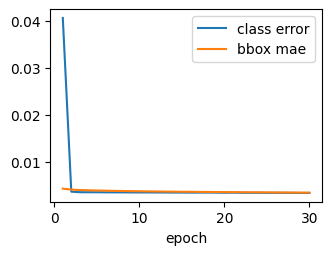

In [91]:
import time
# num_epochs = 20
# For a quick CPU smoke test, use 1.
num_epochs = 30
history = []
net = net.to(device)
started = time.perf_counter()
examples_seen = 0
for epoch in range(num_epochs):
    totals = [0.0] * 4
    net.train()
    for features, target in train_iter: # one batch of 32 images at a time
        trainer.zero_grad()
        X, Y = features.to(device), target.to(device)
        anchors, cls_preds, bbox_preds = net(X) # network predictions
        bbox_labels, bbox_masks, cls_labels = multibox_target(anchors, Y) # compute the ground-truth targets
        loss = calc_loss(cls_preds, cls_labels, bbox_preds, bbox_labels, bbox_masks) # compute the loss
        loss.mean().backward()  # compute gradients (mean() averages the loss over the 32 images)
        trainer.step() # update the weigths
        values = (cls_eval(cls_preds, cls_labels), cls_labels.numel(),
                  bbox_eval(bbox_preds, bbox_labels, bbox_masks), bbox_labels.numel())
        totals = [total + value for total, value in zip(totals, values)]
        examples_seen += X.shape[0]
    cls_err, bbox_mae = 1 - totals[0] / totals[1], totals[2] / totals[3]
    history.append((cls_err, bbox_mae))
    print(f'epoch {epoch + 1}/{num_epochs}: class error {cls_err:.3f}, bbox MAE {bbox_mae:.4f}')
elapsed = time.perf_counter() - started
print(f'{examples_seen / elapsed:.1f} examples/sec on {device}')
plt.plot(range(1, num_epochs + 1), history)
plt.xlabel('epoch')
plt.legend(['class error', 'bbox mae']);

## **Prediction**

During prediction,
the goal is to detect all the objects of interest
on the image.
Below
we read and resize a test image,
converting it to
a four-dimensional tensor that is
required by convolutional layers.


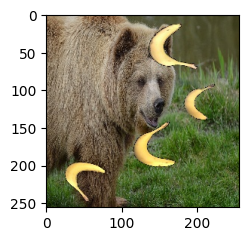

In [92]:
download_file("https://raw.githubusercontent.com/d2l-ai/d2l-en/master/img/banana.jpg", "banana.jpg")
X = read_image('banana.jpg').unsqueeze(0).float()
img = X.squeeze(0).permute(1, 2, 0).to(torch.uint8)
plt.imshow(img)

Using the `multibox_detection` function below,
the predicted bounding boxes
are obtained
from the anchor boxes and their predicted offsets.
Then non-maximum suppression is used
to remove similar predicted bounding boxes.

Note that we need to apply a `softmax` layer on the class predictions to extract probabilities that we can feed into the `multibox_detection` function.

### Your turn
> Complete the code of the `predict()` function below to properly chain the output of the network to the `multibox_detection` function.

In [93]:
def predict(X):
    net.eval()
    with torch.no_grad():
        anchors, cls_preds, bbox_preds = net(X.to(device))
        cls_probs = F.softmax(cls_preds, dim=2).permute(0, 2, 1)
        output = multibox_detection(cls_probs, bbox_preds, anchors, nms_threshold=0.5)
    idx = [i for i, row in enumerate(output[0]) if row[0] != -1]
    return output[0, idx]
output = predict(X)
output[...,:10,:]

tensor([[ 0.0000,  0.2051,  0.1888, -0.1103,  0.7975,  1.1107],
        [ 0.0000,  0.1893,  0.2380, -0.0530,  0.6386,  0.6903],
        [ 0.0000,  0.1256,  0.0892,  0.4196,  0.4828,  0.9939],
        [ 0.0000,  0.1251, -0.0960,  0.1821,  1.2019,  0.7732],
        [ 0.0000,  0.1050, -0.2382,  0.4796,  0.5174,  1.2327],
        [ 0.0000,  0.1047,  0.3364, -0.0971,  0.5974,  0.5160],
        [ 0.0000,  0.1015, -0.1269,  0.1153,  0.4096,  1.0255],
        [ 0.0000,  0.0999,  0.4927,  0.5161,  1.2470,  1.2065],
        [ 0.0000,  0.0980,  0.1345,  0.7363,  0.3894,  1.0541],
        [ 0.0000,  0.0955, -0.1385, -0.3662,  0.3995,  0.5782]],
       device='cuda:0')

Finally, we **display
all the predicted bounding boxes with
confidence 0.9 or above**
as output.


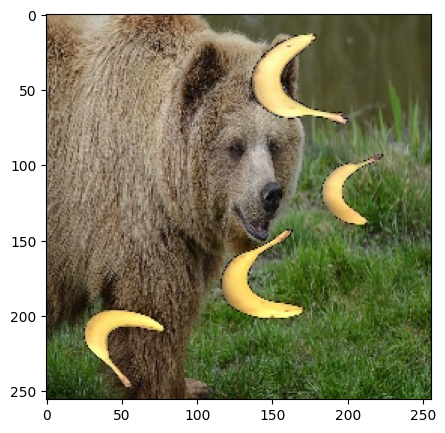

In [94]:
def display(img, output, threshold):
    set_figsize((5, 5))
    fig = plt.imshow(img)
    for row in output:
        score = float(row[1])
        if score < threshold:
            continue
        h, w = img.shape[:2]
        bbox = [row[2:6] * torch.tensor((w, h, w, h), device=row.device)]
        show_bboxes(fig.axes, bbox, '%.2f' % score, 'r')

display(img, output.cpu(), threshold=0.3)

In [95]:
df_val = pd.read_csv(os.path.join(DATA_DIR, 'val.csv'))
df_val = df_val[(df_val.x2 > df_val.x1) & (df_val.y2 > df_val.y1)]

ious = []
for _, row in df_val.iterrows():
    X_val = read_image(os.path.join(DATA_DIR, 'val', row['img_name'])).unsqueeze(0).float()
    out = predict(X_val)
    if out.shape[0] == 0:          # no detection at all
        ious.append(0.0)
        continue
    best = out[out[:, 1].argmax()]                     # detection with the highest confidence
    h, w = X_val.shape[-2:]
    pred_box = (best[2:6].cpu() * torch.tensor([w, h, w, h])).unsqueeze(0)
    true_box = torch.tensor([[row['x1'], row['y1'], row['x2'], row['y2']]], dtype=torch.float32)
    ious.append(box_iou(pred_box, true_box).item())

ious = torch.tensor(ious)
print(f'mean IoU on val: {ious.mean():.3f}')
print(f'images with IoU > 0.5: {(ious > 0.5).float().mean() * 100:.1f} %')

mean IoU on val: 0.510
images with IoU > 0.5: 57.8 %


## Summary

* Single shot multibox detection is a multiscale object detection model. Via its base network and several multiscale feature map blocks, single-shot multibox detection generates a varying number of anchor boxes with different sizes, and detects varying-size objects by predicting classes and offsets of these anchor boxes (thus the bounding boxes).
* When training the single-shot multibox detection model, the loss function is calculated based on the predicted and labeled values of the anchor box classes and offsets.



## Improvements

Can you improve the single-shot multibox detection by improving the loss function? For example, replace $\ell_1$ norm loss with smooth $\ell_1$ norm loss for the predicted offsets. This loss function uses a square function around zero for smoothness, which is controlled by the hyperparameter $\sigma$:

$$
f(x) =
    \begin{cases}
    (\sigma x)^2/2,& \textrm{if }|x| < 1/\sigma^2\\
    |x|-0.5/\sigma^2,& \textrm{otherwise}
    \end{cases}
$$

When $\sigma$ is very large, this loss is similar to the $\ell_1$ norm loss. When its value is smaller, the loss function is smoother.


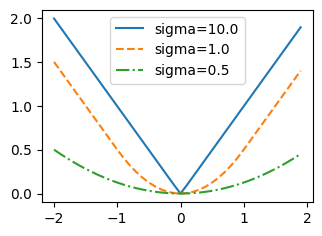

In [96]:
def smooth_l1(data, scalar):
    out = []
    for i in data:
        if abs(i) < 1 / (scalar ** 2):
            out.append(((scalar * i) ** 2) / 2)
        else:
            out.append(abs(i) - 0.5 / (scalar ** 2))
    return torch.tensor(out)

sigmas = [10, 1, 0.5]
lines = ['-', '--', '-.']
x = torch.arange(-2, 2, 0.1)
set_figsize()

for l, s in zip(lines, sigmas):
    y = smooth_l1(x, scalar=s)
    plt.plot(x, y, l, label='sigma=%.1f' % s)
plt.legend();

Besides, in the experiment we used cross-entropy loss for class prediction:
denoting by $p_j$ the predicted probability for the ground-truth class $j$, the cross-entropy loss is $-\log p_j$.


We can also use the [focal loss](https://openaccess.thecvf.com/content_iccv_2017/html/Lin_Focal_Loss_for_ICCV_2017_paper.html): given hyperparameters $\gamma > 0$
and $\alpha > 0$, this loss is defined as:

$$ - \alpha (1-p_j)^{\gamma} \log p_j.$$

As we can see, increasing $\gamma$
can effectively reduce the relative loss
for well-classified examples (e.g., $p_j > 0.5$)
so the training
can focus more on those difficult examples that are misclassified.


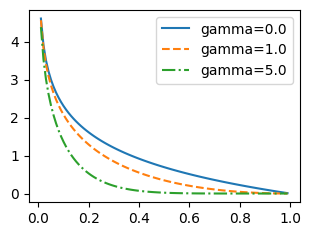

In [97]:
def focal_loss(gamma, x):
    return -(1 - x) ** gamma * torch.log(x)

x = torch.arange(0.01, 1, 0.01)
for l, gamma in zip(lines, [0, 1, 5]):
    y = plt.plot(x, focal_loss(gamma, x), l, label='gamma=%.1f' % gamma)
plt.legend();

In [98]:
test_dir = os.path.join(DATA_DIR, 'test')
rows = []
for img_name in sorted(f for f in os.listdir(test_dir) if f.endswith('.png')):
    X_test = read_image(os.path.join(test_dir, img_name)).unsqueeze(0).float()
    h, w = X_test.shape[-2:]
    out = predict(X_test)
    if out.shape[0] > 0:
        best = out[out[:, 1].argmax()]                 # most confident detection (1 object per image)
        class_id = int(best[0])
        x1, y1, x2, y2 = (best[2:6].cpu() * torch.tensor([w, h, w, h])).tolist()
    else:                                              # no detection: fall back to the whole image
        class_id, x1, y1, x2, y2 = 0, 0, 0, w, h
    x1, x2 = [int(round(min(max(v, 0), w))) for v in (x1, x2)]
    y1, y2 = [int(round(min(max(v, 0), h))) for v in (y1, y2)]
    rows.append({'img_name': img_name, 'class_id': class_id, 'x1': x1, 'x2': x2, 'y1': y1, 'y2': y2})

submission = pd.DataFrame(rows, columns=['img_name', 'class_id', 'x1', 'x2', 'y1', 'y2'])
submission.to_csv('test.csv', index=False)
print(len(submission), 'rows written to test.csv')
submission.head()

67 rows written to test.csv


,img_name,class_id,x1,x2,y1,y2
0,02b02e07-6daa-4656-9602-7f8ef6c5f950.png,0,164,235,142,256
1,0463f20b-36e9-4565-94e2-45c0bbc7e254.png,0,104,170,62,209
2,083cd46e-bbed-4aed-be9f-9b1718988ead.png,0,54,206,0,256
3,1244adcb-4782-4dfd-a393-514a008691dc.png,0,70,162,34,256
4,1834d5d2-5ab0-4e04-9842-d136828f555f.png,0,69,167,21,219


In [99]:
files.download('test.csv')

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>